# 03 · Fare econometrics (R)

The other notebooks ask *when* to buy. This one asks *why* fares move the
way they do, using panel econometrics: the same 50,000 trips observed day
after day.

**Key takeaways**
1. **The advance-purchase deadlines are real.** Holding the trip fixed, the
   fare jumps beyond the smooth trend on the day each deadline passes:
   **+5.0% at 21 days, +9.7% at 14 days, +2.2% at 7 days** (all p < 0.001).
   The biggest late jump actually comes 5 days out.
2. **"Search on a Tuesday" is a myth.** Within the same trip, the day I
   search moves the fare by less than 1%. **The day I fly matters a lot:**
   Tuesday and Wednesday flights are cheapest, Friday flights cost about 24%
   more and Sunday flights about 35% more.
3. **The Spirit effect.** Routes where Spirit or Frontier has a real presence
   have fares about **36% lower**, holding distance and concentration fixed.
   Once that's controlled for, concentration (HHI) itself no longer
   matters.
4. **Price moves partly reverse.** A 10% jump is followed on average by
   about a 3% move back the next day, and the variance ratio falls to 0.23
   over 20 days, far from the random walk's 1.0. That's why waiting after a
   price spike can pay.

In [1]:
suppressPackageStartupMessages({
  library(DBI); library(duckdb); library(data.table)
  library(fixest); library(ggplot2); library(modelsummary)
})
options(repr.plot.width = 9, repr.plot.height = 4.2, repr.plot.res = 110, width = 120)

data_dir <- Sys.getenv("FLIGHT_DATA_DIR",
                       file.path(Sys.getenv("USERPROFILE"), "data", "flight-pricing"))
con <- dbConnect(duckdb(shared_home = FALSE))
q <- function(sql) as.data.table(dbGetQuery(con, sql))
cheapest <- file.path(data_dir, "processed", "cheapest_daily.parquet")
itin <- file.path(data_dir, "processed", "itineraries.parquet")

# Chart style shared with the Python notebooks
blue <- "#2a78d6"; orange <- "#eb6834"; muted <- "#52514e"
theme_set(theme_minimal(base_size = 11) + theme(
  plot.background = element_rect(fill = "#fcfcfb", colour = NA),
  panel.grid.minor = element_blank(), panel.grid.major.x = element_blank(),
  plot.title = element_text(face = "bold", hjust = 0, colour = "#0b0b0b"),
  axis.title = element_text(colour = muted), axis.text = element_text(colour = muted)))

show_table <- function(models, ...) {
  print(modelsummary(models, output = "markdown", gof_map = c("nobs", "r.squared"), ...))
}

## The data: a panel of trips

Each row is the cheapest fare for one **trip** (route × flight date) on one
search day, the same table as notebooks 02–09. That's about 2 million rows
covering 50,759 trips.

In [2]:
d <- q(sprintf("
  SELECT origin, dest, origin || '-' || dest AS route, flightDate, searchDate,
         days_ahead, fare, ln(fare) AS log_fare,
         dayname(searchDate) AS search_dow, dayname(flightDate) AS flight_dow,
         monthname(flightDate) AS flight_month
  FROM '%s' WHERE days_ahead BETWEEN 1 AND 60", cheapest))
d[, trip := paste(route, flightDate)]
dow_levels <- c("Monday", "Tuesday", "Wednesday", "Thursday", "Friday", "Saturday", "Sunday")
d[, `:=`(search_dow = factor(search_dow, dow_levels), flight_dow = factor(flight_dow, dow_levels))]
cat(format(nrow(d), big.mark = ","), "rows,", format(uniqueN(d$trip), big.mark = ","), "trips,",
    uniqueN(d$route), "routes\n")

1,987,439 rows, 50,759 trips, 235 routes


## 1. The booking curve, with trip fixed effects

Notebook 02 drew the booking curve by dividing each fare by its trip's
median. The econometric version is a **fixed-effects regression**:

$$\log P_{it} = \alpha_i + \sum_{d \ne 30} \beta_d \,\mathbf{1}[t = d] + \varepsilon_{it}$$

- $\alpha_i$ is a separate intercept for every trip, which absorbs
  everything about the trip that doesn't change over time (route, date,
  season, demand).
- $\beta_d$ is then the average log-fare difference between $d$ days out and
  30 days out **for the same trip**.
- Standard errors are **clustered by route**, because errors on the same
  route are correlated (the same reason as the cluster bootstrap in
  notebook 09).

NOTE: 252 fixed-effect singletons were removed (252 observations).



days,pct,ci_low,ci_high
<int>,<dbl>,<dbl>,<dbl>
60,0.126,0.112,0.139
45,0.031,0.026,0.036
22,0.006,0.002,0.010
21,0.004,0.000,0.009
20,0.053,0.044,0.062
15,0.054,0.043,0.065
14,0.056,0.044,0.067
13,0.173,0.151,0.195
8,0.216,0.190,0.242


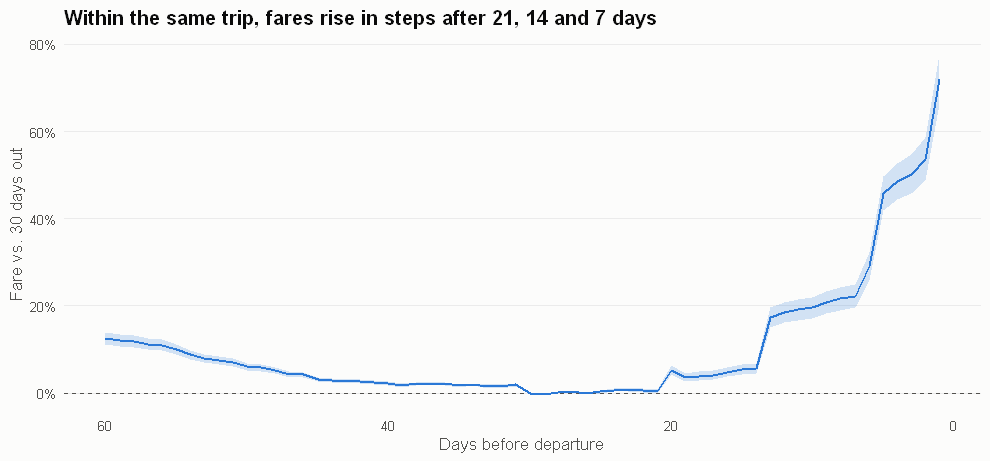

In [3]:
curve <- feols(log_fare ~ i(days_ahead, ref = 30) | trip, data = d, cluster = ~route)
ct <- as.data.table(coeftable(curve), keep.rownames = "term")
ct[, days := as.integer(sub("days_ahead::", "", term))]
ct <- rbind(ct, data.table(days = 30L, Estimate = 0, `Std. Error` = 0), fill = TRUE)
ct[, `:=`(pct = exp(Estimate) - 1,
          lo = exp(Estimate - 1.96 * `Std. Error`) - 1, hi = exp(Estimate + 1.96 * `Std. Error`) - 1)]

ggplot(ct, aes(days, pct)) +
  geom_hline(yintercept = 0, linetype = "dashed", colour = muted) +
  geom_ribbon(aes(ymin = lo, ymax = hi), fill = blue, alpha = 0.2) +
  geom_line(colour = blue, linewidth = 0.9) +
  scale_x_reverse() + scale_y_continuous(labels = scales::percent) +
  labs(title = "Within the same trip, fares rise in steps after 21, 14 and 7 days",
       x = "Days before departure", y = "Fare vs. 30 days out")

ct[days %in% c(60, 45, 22, 21, 20, 15, 14, 13, 8, 7, 6, 1), .(days, pct = round(pct, 3),
   ci_low = round(lo, 3), ci_high = round(hi, 3))][order(-days)]

Compared with the same trip 30 days out:

- **60 days out, fares are about 13% higher**, and they ease down to the
  30-day level by about 30 days out. That slow decline is what the dynamic
  programming policy captures from 60 days out (notebook 07).
- **Steps right after 21, 14 and 7 days:** +0.4% at 21 → +5.3% at 20, +5.6%
  at 14 → +17.3% at 13, and +22% at 7 → +29% at 6.
- **The biggest late jump is between 6 and 5 days out** (to about +46%),
  and the day before departure is +72%.

The confidence band is narrow everywhere: with 2 million observations, even
clustered by route, the shape is very precisely estimated.

## 2. Are the 21/14/7-day steps real? (a discontinuity test)

If cheap fare classes close at 21, 14 and 7 days, the fare should **jump on
the day the deadline passes**, more than the smooth upward trend would
predict. I test that on day-to-day changes in log fare (consecutive days
only):

$$\Delta \log P_{it} = \gamma_{21} D^{21}_t + \gamma_{14} D^{14}_t + \gamma_{7} D^{7}_t
+ f(t) + \alpha_{\text{route}} + \varepsilon_{it}$$

- $D^{21}_t = 1$ on the day the 21-day deadline has just passed (20 days
  out), and likewise for 14 and 7.
- $f(t)$ is a smooth cubic trend in days to departure, so $\gamma$ measures
  the **extra** jump at the deadline beyond the general climb.
- This is a regression discontinuity design: compare what happens right at
  the cutoff with the trend on either side.

In [4]:
setorder(d, trip, -days_ahead)
d[, `:=`(prev_log_fare = shift(log_fare), prev_days = shift(days_ahead)), by = trip]
ch <- d[prev_days == days_ahead + 1]
ch[, `:=`(dlog = log_fare - prev_log_fare,
          passed21 = as.integer(days_ahead == 20), passed14 = as.integer(days_ahead == 13),
          passed7 = as.integer(days_ahead == 6))]
rd <- feols(dlog ~ passed21 + passed14 + passed7 + poly(days_ahead, 3) | route,
            data = ch, cluster = ~route)
show_table(list("Daily change in log fare" = rd), coef_omit = "poly",
           coef_rename = c(passed21 = "Day after 21-day deadline", passed14 = "Day after 14-day deadline",
                           passed7 = "Day after 7-day deadline"), stars = TRUE)


+---------------------------+--------------------------+
|                           | Daily change in log fare |
+===========================+==========================+
| Day after 21-day deadline | 0.050***                 |
+---------------------------+--------------------------+
|                           | (0.004)                  |
+---------------------------+--------------------------+
| Day after 14-day deadline | 0.097***                 |
+---------------------------+--------------------------+
|                           | (0.006)                  |
+---------------------------+--------------------------+
| Day after 7-day deadline  | 0.022***                 |
+---------------------------+--------------------------+
|                           | (0.004)                  |
+---------------------------+--------------------------+
| Num.Obs.                  | 1799252                  |
+---------------------------+--------------------------+
| R2                        | 

All three deadline jumps are large and highly significant:

| Deadline | Extra jump beyond the trend | Standard error |
|---|---|---|
| 21 days | +5.0% | 0.4% |
| 14 days | +9.7% | 0.6% |
| 7 days | +2.2% | 0.4% |

The 14-day deadline is the most important. The 7-day effect is smaller than
the chart suggests because the steepest late jump happens 5 days out, not 6.
That could be another common fare rule, or simply the last-minute climb
accelerating.

**Why it matters for buying:** if I'm going to wait, I should **buy before a
deadline passes**, never just after. This is exactly the "cliff" pattern in
notebook 05, now confirmed statistically.

## 3. Is it cheaper to search on a Tuesday?

A popular rule says to **search** (book) on a Tuesday. Within a trip,
the day of the week I search changes as departure approaches, so I can
test it while holding the trip and the days-to-departure fixed:

$$\log P_{it} = \alpha_i + \delta_t + \sum_{w \ne \text{Tue}} \theta_w\, \mathbf{1}[\text{search day} = w] + \varepsilon_{it}$$

with trip fixed effects $\alpha_i$ and days-to-departure fixed effects
$\delta_t$. Separately, I check whether the **flight's** day of week matters,
comparing flights on the same route and in the same month.

In [5]:
search_dow <- feols(log_fare ~ i(search_dow, ref = "Tuesday") | trip + days_ahead,
                    data = d, cluster = ~route)
flight_dow <- feols(log_fare ~ i(flight_dow, ref = "Tuesday") | route + flight_month + days_ahead,
                    data = d, cluster = ~route)
show_table(list("Search day (within trip)" = search_dow, "Flight day (within route)" = flight_dow),
           coef_rename = function(x) sub(".*::", "", x), stars = TRUE)

NOTE: 252/0 fixed-effect singletons were removed (252 observations).



NOTE: 1/0/0 fixed-effect singleton was removed (1 observation).




+-----------+--------------------------+---------------------------+
|           | Search day (within trip) | Flight day (within route) |
+===========+==========================+===========================+
| Monday    | 0.001                    | 0.168***                  |
+-----------+--------------------------+---------------------------+
|           | (0.001)                  | (0.007)                   |
+-----------+--------------------------+---------------------------+
| Wednesday | 0.009***                 | -0.007+                   |
+-----------+--------------------------+---------------------------+
|           | (0.001)                  | (0.004)                   |
+-----------+--------------------------+---------------------------+
| Thursday  | 0.006***                 | 0.161***                  |
+-----------+--------------------------+---------------------------+
|           | (0.001)                  | (0.006)                   |
+-----------+--------------------

**Search day:** the largest effect is **less than 1%** (searching on a
Wednesday is 0.9% more expensive than on a Tuesday), and Monday, Saturday
and Sunday are no different from Tuesday. The differences are statistically
detectable only because there are 2 million observations, and they're far too
small to matter. **The "book on a Tuesday" rule is a myth**, at least for
these routes in 2022.

**Flight day:** this one matters. Compared with flying on a Tuesday, on the
same route and in the same month:

| Fly on | Fare difference |
|---|---|
| Wednesday | about the same |
| Saturday | +11% |
| Thursday | +17% |
| Monday | +18% |
| Friday | +24% |
| Sunday | +35% |

(Converted from the log coefficients with $e^{eta} - 1$.)

So the useful travel advice is the opposite of the myth: **it doesn't matter
when you search, but it matters a lot when you fly.** Midweek flights avoid
the business-commuter and weekend-leisure peaks.

## 4. Competition and the "Spirit effect"

Do routes with more competition have lower fares? For each route I
measure:

- **HHI** (Herfindahl–Hirschman index), the standard concentration measure:
  $\text{HHI} = \sum_a s_a^2$, where $s_a$ is airline $a$'s share of the
  options listed on the route. It's 1 for a monopoly and $1/n$ for $n$ equal
  airlines.
- Whether an **ultra-low-cost carrier** (Spirit or Frontier) has a real
  presence (at least 5% of options).
- **Distance**, since longer flights cost more regardless of competition.

Then I regress each route's typical cheapest fare (median log fare 22–30 days
out, before the late climb) on these, with heteroskedasticity-robust standard
errors. That's one row per route (234 routes have airline listings).

In [6]:
shares <- q(sprintf("
  WITH a AS (
    SELECT startingAirport || '-' || destinationAirport AS route,
           split_part(segmentsAirlineName, '||', 1) AS airline, count(*) AS n
    FROM '%s' GROUP BY ALL),
  s AS (SELECT route, airline, n / sum(n) OVER (PARTITION BY route) AS share FROM a)
  SELECT route, sum(share * share) AS hhi,
         sum(CASE WHEN airline IN ('Spirit Airlines', 'Frontier Airlines') THEN share ELSE 0 END) AS ulcc_share,
         count(*) AS n_airlines
  FROM s GROUP BY route", itin))
dist <- q(sprintf("
  SELECT startingAirport || '-' || destinationAirport AS route, median(totalTravelDistance) AS miles
  FROM '%s' WHERE isNonStop GROUP BY 1", itin))
routes <- d[days_ahead %between% c(22, 30), .(log_fare = median(log_fare), fare = median(fare)), by = route]
routes <- merge(merge(routes, shares, by = "route"), dist, by = "route", all.x = TRUE)
routes[, ulcc := as.integer(ulcc_share >= 0.05)]
cat(nrow(routes), "routes;", sum(is.na(routes$miles)), "without a nonstop distance\n")

comp <- list(
  "Log fare" = feols(log_fare ~ log(miles) + hhi + ulcc, data = routes, vcov = "hetero"),
  "Log fare (no ULCC term)" = feols(log_fare ~ log(miles) + hhi, data = routes, vcov = "hetero"))
show_table(comp, coef_rename = c("log(miles)" = "Log distance", hhi = "HHI (concentration)",
                                 ulcc = "Spirit/Frontier present"), stars = TRUE)

234 routes; 29 without a nonstop distance


NOTE: 29 observations removed because of NA values (RHS: 29).



NOTE: 29 observations removed because of NA values (RHS: 29).




+-------------------------+-----------+-------------------------+
|                         | Log fare  | Log fare (no ULCC term) |
+=========================+===========+=========================+
| (Intercept)             | 2.306***  | 1.710***                |
+-------------------------+-----------+-------------------------+
|                         | (0.325)   | (0.341)                 |
+-------------------------+-----------+-------------------------+
| Log distance            | 0.372***  | 0.371***                |
+-------------------------+-----------+-------------------------+
|                         | (0.037)   | (0.044)                 |
+-------------------------+-----------+-------------------------+
| HHI (concentration)     | 0.529     | 1.785***                |
+-------------------------+-----------+-------------------------+
|                         | (0.366)   | (0.359)                 |
+-------------------------+-----------+-------------------------+
| Spirit/

- **Distance:** a 10% longer route has about 3.7% higher fares (an elasticity
  of 0.37), as expected.
- **Spirit/Frontier presence:** fares are $e^{-0.446} - 1 \approx$ **36% lower**
  on routes where an ultra-low-cost carrier has at least 5% of listings.
- **Concentration (HHI):** on its own (second column) it looks like more
  concentrated routes are pricier. But once ULCC presence is in the model,
  the HHI effect shrinks and loses significance. Much of what looked like a
  "competition" effect is really a "budget airline" effect.
- Adding ULCC presence raises $R^2$ from 0.38 to 0.57.

**The caveat (endogeneity).** This is correlation, not causation. Spirit and
Frontier *choose* which routes to fly, and they tend to pick leisure routes
where travelers are price-sensitive. Those routes might be cheap anyway. A
causal estimate would need something like the change in fares when a ULCC
enters a route, compared with routes it didn't enter (a difference-in-
differences design), which needs data across years. Also, HHI here is based
on the share of **listings**, not passengers, since the data has no ticket
sales. And 29 routes have no nonstop flight to measure distance, so the
regression uses 205 routes.

**Since then:** Spirit Airlines ceased operations in 2026, so this is a
snapshot of a market that no longer exists in the same form. The question
is still a good one to revisit with newer data: if fares rose on the routes
Spirit left, compared with similar routes it never served, that would be a
much more convincing (causal) estimate of the budget-carrier effect than this
cross-section.

## 5. Do price moves reverse?

If a drop tends to be followed by a rise (and vice versa), price changes are
**negatively autocorrelated**, and fares behave less like a random walk
than like a series that keeps getting pulled back.

**Autocorrelation:** regress today's change on yesterday's change, with
route fixed effects:

$$\Delta \log P_{it} = \rho\, \Delta \log P_{i,t+1} + \alpha_{\text{route}} + \varepsilon_{it}$$

**Variance ratio:** for a random walk, the variance of a $q$-day change is
$q$ times the variance of a 1-day change, so

$$\text{VR}(q) = \frac{\operatorname{Var}(\log P_{t} - \log P_{t+q})}{q\cdot \operatorname{Var}(\log P_{t} - \log P_{t+1})} = 1$$

A ratio below 1 means moves partly cancel out over time (mean reversion).
I exclude the last 7 days, where the steady climb would mask reversion.

In [7]:
ch[, `:=`(prev_dlog = shift(dlog), prev_days2 = shift(days_ahead)), by = trip]
ar <- feols(dlog ~ prev_dlog | route, data = ch[prev_days2 == days_ahead + 1 & days_ahead > 7],
            cluster = ~route)
show_table(list("Today's change" = ar), coef_rename = c(prev_dlog = "Yesterday's change"), stars = TRUE)

vr <- rbindlist(lapply(c(2, 5, 10, 20), function(qd) {
  x <- d[days_ahead > 7]
  x <- merge(x[, .(trip, days_ahead, log_fare)],
             x[, .(trip, days_ahead = days_ahead - qd, log_fare_q = log_fare)], by = c("trip", "days_ahead"))
  data.table(q = qd, var_q = var(x$log_fare - x$log_fare_q))
}))
var1 <- var(ch[days_ahead > 7, dlog])
vr[, `:=`(variance_ratio = round(var_q / (q * var1), 3))]
vr[, .(q, variance_ratio)]


+--------------------+----------------+
|                    | Today's change |
+====================+================+
| Yesterday's change | -0.284***      |
+--------------------+----------------+
|                    | (0.003)        |
+--------------------+----------------+
| Num.Obs.           | 1376339        |
+--------------------+----------------+
| R2                 | 0.081          |
+====================+================+
| + p < 0.1, * p < 0.05, ** p <       |
| 0.01, *** p < 0.001                 |
+====================+================+ 


q,variance_ratio
<dbl>,<dbl>
2,0.718
5,0.454
10,0.324
20,0.226


**Autocorrelation of −0.28:** a 10% jump up today is followed on average by
about a 2.8% move back down the next day. That's strong, highly significant
reversal.

**Variance ratios well below 1:** over 20 days, fares move only about 23% as
much as a random walk with the same daily volatility would. Daily moves
largely cancel out.

*My guess at why:* part of it is fares bouncing between fare classes as
seats sell and get released, and part is the "cheapest option" switching
between itineraries (notebook 02). It's similar to **bid-ask bounce** in
stock prices, where trades alternating between the bid and the ask create
negative autocorrelation in observed price changes.

This is the same pull-back that the jump model in notebook 07 estimated
(κ ≈ −0.2), measured a different way.

## What this means for the buy-or-wait problem

1. **Days to departure and deadline proximity** are the main drivers of fare
   changes for a given trip. That's why they rank at the top of the model's
   inputs (notebook 06), and why the DP thresholds jump at the deadlines.
2. **Buy before a deadline, not after.** Each deadline adds 2–10% overnight.
3. **Don't wait for a particular search day**, because it doesn't matter.
   Choose the flight day instead, if I'm flexible.
4. **After a price spike, waiting often pays**, because jumps partly
   reverse. After a drop, buy before it reverts.
5. **Routes with budget airlines are cheaper** but also more volatile, and
   their listed fares exclude bag fees (a limitation from notebook 02).